<p style="text-align:center">
    <a href="https://www.ict.mahidol.ac.th/en/" target="_blank">
    <img src="https://www3.ict.mahidol.ac.th/ICTSurveysV2/Content/image/MUICT2.png" width="400" alt="Faculty of ICT">
    </a>
</p>

# ITGE275: Economics
## Session 9: The Public Ledger – Fiscal Policy and Taxation

**Topic:** Fiscal Policy, Tax Brackets, and the Multiplier Effect.

---
### 👦 Student Information 👧

**Your name:** Qimin Zhu 
**ID:** 6888143

---

### **1. Introduction: The Government as an Economic Agent**

The Government is the largest single agent in the economy. It has two main tools to influence the economy, known as **Fiscal Policy**:

1.  **Government Spending ($G$):** Building roads, paying salaries, subsidies.
2.  **Taxation ($T$):** Collecting money from households and firms.

**The Budget Balance:**
* $T > G$: Budget Surplus.
* $T < G$: Budget Deficit (Must borrow/issue bonds).

In this session, we will write code to calculate **Personal Income Tax** and simulate the **Fiscal Multiplier Effect** of government stimulus.

In [1]:
# Step 1: Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

# Configure plotting style
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries loaded successfully.")

Libraries loaded successfully.


### **2. The Progressive Tax Algorithm**

Most countries use a **Progressive Tax System**. This means high earners pay a higher *percentage*, not just a higher amount.

**Thai Personal Income Tax Brackets (Simplified 2024):**
* 0 - 150,000 THB: **Exempt (0%)**
* 150,001 - 300,000 THB: **5%**
* 300,001 - 500,000 THB: **10%**
* 500,001 - 750,000 THB: **15%**
* 750,001 - 1,000,000 THB: **20%**
* 1,000,001 - 2,000,000 THB: **25%**
* 2,000,001 - 5,000,000 THB: **30%**
* Over 5,000,000 THB: **35%**

Let's write a function to calculate tax based on **Net Income** (Income after deductions).

In [2]:
def calculate_thai_tax(salary_monthly, bonus, deductions):
    # 1. Calculate Annual Income
    total_income = (salary_monthly * 12) + bonus
    
    # 2. Apply Deductions (Standard expenses + specific deductions)
    # Standard deduction: 50% of income but not more than 100,000 THB
    standard_deduction = min(total_income * 0.5, 100000)
    personal_allowance = 60000 # Standard personal care allowance
    
    net_income = total_income - standard_deduction - personal_allowance - deductions
    net_income = max(0, net_income) # Cannot be negative
    
    # 3. Calculate Tax based on Brackets
    # Format: (Threshold, Rate)
    brackets = [
        (150000, 0.00),
        (300000, 0.05),
        (500000, 0.10),
        (750000, 0.15),
        (1000000, 0.20),
        (2000000, 0.25),
        (5000000, 0.30),
        (float('inf'), 0.35)
    ]
    
    tax_payable = 0
    previous_threshold = 0
    remaining_income = net_income
    
    tax_breakdown = []
    
    for threshold, rate in brackets:
        if remaining_income <= 0:
            break
            
        # Calculate taxable amount in this specific bracket
        bracket_range = threshold - previous_threshold
        taxable_in_bracket = min(remaining_income, bracket_range)
        
        tax_amount = taxable_in_bracket * rate
        tax_payable += tax_amount
        
        if tax_amount > 0:
            tax_breakdown.append(f"Income {previous_threshold:,.0f}-{threshold:,.0f}: {taxable_in_bracket:,.0f} * {rate*100}% = {tax_amount:,.0f} THB")
        
        remaining_income -= taxable_in_bracket
        previous_threshold = threshold
        
    # 4. Metrics
    effective_tax_rate = (tax_payable / total_income) * 100 if total_income > 0 else 0
    marginal_tax_rate = next((r for t, r in brackets if net_income < t), 0.35) * 100

    # 5. Output Report
    print(f"--- TAX CALCULATION REPORT ---")
    print(f"Total Income:      {total_income:,.0f} THB")
    print(f"Net Taxable Income:{net_income:,.0f} THB (After {standard_deduction+personal_allowance+deductions:,.0f} deductions)")
    print(f"------------------------------")
    for line in tax_breakdown:
        print(line)
    print(f"------------------------------")
    print(f"TOTAL TAX PAYABLE: {tax_payable:,.2f} THB")
    print(f"Effective Tax Rate:{effective_tax_rate:.2f}% (Actual % of total income paid)")
    print(f"Marginal Tax Rate: {marginal_tax_rate:.0f}% (Tax rate on next 1 THB earned)")

# Interactive Widget
style = {'description_width': 'initial'}
widgets.interactive(calculate_thai_tax,
                    salary_monthly=widgets.IntSlider(min=15000, max=200000, step=5000, value=30000, description='Monthly Salary', style=style),
                    bonus=widgets.IntSlider(min=0, max=500000, step=10000, value=20000, description='Annual Bonus', style=style),
                    deductions=widgets.IntSlider(min=0, max=500000, step=5000, value=9000, description='Deductions (SSO/LTF)', style=style)
)

interactive(children=(IntSlider(value=30000, description='Monthly Salary', max=200000, min=15000, step=5000, s…

### **3. Fiscal Policy: The Multiplier Effect**

When the government spends money ($G$), it creates income for someone. That person spends part of it, creating income for someone else. This ripple effect is the **Fiscal Multiplier**.

$$ \text{Multiplier} = \frac{1}{1 - MPC} $$

* **MPC (Marginal Propensity to Consume):** If I give you $1, how much do you spend? (e.g., 0.8 means you spend 80 cents).

**Example:**
* Government spends 100 Million on a bridge.
* Workers get 100M. They spend 80M (MPC=0.8).
* Shopkeepers get 80M. They spend 64M.
* ... Total GDP increase > 100M.

Let's simulate a "Digital Wallet Stimulus."

In [3]:
def fiscal_simulator(stimulus_amount, mpc):
    # Calculate Theoretical Multiplier
    multiplier = 1 / (1 - mpc)
    total_effect = stimulus_amount * multiplier
    
    # Simulation of Rounds
    rounds = 10
    spending_in_round = [stimulus_amount]
    current_amount = stimulus_amount
    
    for i in range(rounds):
        current_amount = current_amount * mpc
        spending_in_round.append(current_amount)
        
    # Visualization
    cumulative_gdp = np.cumsum(spending_in_round)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    ax.bar(range(len(spending_in_round)), spending_in_round, label='New Spending per Round', color='lightblue')
    ax.plot(range(len(spending_in_round)), cumulative_gdp, label='Cumulative GDP Impact', color='green', marker='o')
    
    ax.set_title(f'Fiscal Multiplier Simulation (MPC={mpc})', fontsize=14)
    ax.set_xlabel('Spending Rounds (Ripple Effect)')
    ax.set_ylabel('Money Value (Million THB)')
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    print(f"Initial Stimulus: {stimulus_amount} Million")
    print(f"Theoretical Multiplier: {multiplier:.2f}x")
    print(f"Total GDP Created (approx): {total_effect:.2f} Million")
    
    plt.show()

widgets.interactive(fiscal_simulator,
                    stimulus_amount=widgets.IntSlider(min=100, max=1000, value=500, description='Stimulus (M THB)'),
                    mpc=widgets.FloatSlider(min=0.1, max=0.9, step=0.1, value=0.6, description='MPC (Spend Rate)')
)

interactive(children=(IntSlider(value=500, description='Stimulus (M THB)', max=1000, min=100), FloatSlider(val…

### **4. Visualization: Where does the money go?**

Let's look at a simplified breakdown of a Government Budget to understand national priorities.

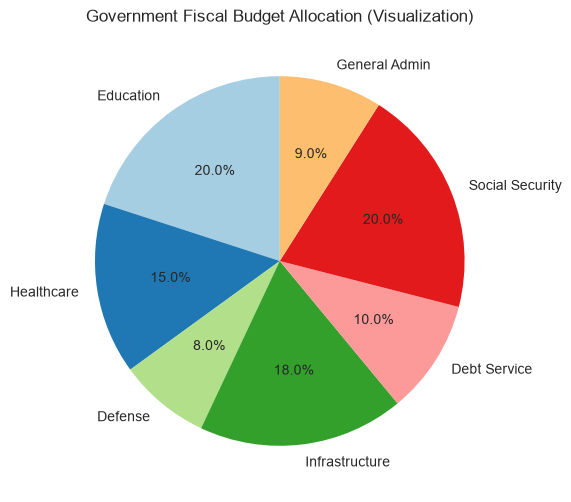

In [4]:
# Synthetic Budget Data (Mimicking a typical developing economy structure)
budget_categories = ['Education', 'Healthcare', 'Defense', 'Infrastructure', 'Debt Service', 'Social Security', 'General Admin']
budget_amounts = [20, 15, 8, 18, 10, 20, 9] # Percentages

plt.figure(figsize=(10, 6))
colors = plt.cm.Paired(np.arange(len(budget_categories)))
plt.pie(budget_amounts, labels=budget_categories, autopct='%1.1f%%', colors=colors, startangle=90)
plt.title('Government Fiscal Budget Allocation (Visualization)')
plt.show()

---
## **5. Homework Assignment**

**Objective:** Apply tax logic and fiscal theory to make decisions.

#### **Question 1: The Tax Shield Strategy**
You earn **60,000 THB/month** and get a **100,000 THB bonus**.
1.  Use the `calculate_thai_tax` function to find your tax payable with **0 deductions** (set deductions=0).
2.  Now, imagine you invest **100,000 THB** in a Tax-Deductible Fund (SSF/RMF). Set deductions=100000.
3.  Calculate your **Tax Saving** (Tax without deduction - Tax with deduction).
4.  Was investing 100k to save that amount of tax worth it? (Calculate the "Instant Return" on investment from the tax save).

In [7]:
# # === HOMEWORK SPACE: QUESTION 1 ===
# # Scenario A: 0 Deductions
# # calculate_thai_tax(60000, 100000, 0)

# Total Income:      820,000 THB
# Net Taxable Income:560,000 THB (After 260,000 deductions)
# TOTAL TAX PAYABLE: 36,500.00 THB

# # Scenario B: 100k Deductions
# # calculate_thai_tax(60000, 100000, 100000)

# Total Income:      820,000 THB
# Net Taxable Income:660,000 THB (After 160,000 deductions)
# TOTAL TAX PAYABLE: 51,500.00 THB

# # Calculate Savings
# 36500 - 51500 = -15000

# 15000/100000 = 15%

# Saved 15000, when invested 100000

#### **Question 2: VAT vs. Income Tax**
The government needs to fund a new electric train line. It can either:
A. Raise VAT (Value Added Tax) from 7% to 10%.
B. Raise Income Tax on the rich (Top bracket 35% -> 40%).

**Task:** Discuss the trade-off. Which is more **Efficient** (harder to evade, steady revenue)? Which is more **Fair** (Progressive vs Regressive)?

*(Write your answers in the Markdown cell below)*

=== HOMEWORK SPACE: QUESTION 2 ===



Raise VAT from 7% to 10% would be applied to everybody, but raise top bracket from 35% to 40% will only cover the rich income group.
Option A will affects everyone, if the counter is developing country it might not be a efficient choice. If the salary is unideal and the VAT raised, it might cause unwanted issue among the country economy, such as people don't want to work harder, saving more, and spend less.
In conclusion, option A is more efficient and fair, it covers everyone, but option B is more realistic for developing country.